# Diet Problem (LP)

This problem is taken from Prof. Eli Olinick's [Operations Research Models](https://s2.smu.edu/~olinick/cse3360/) course [Mathematical Programming Examples](https://s2.smu.edu/~olinick/cse3360/lectures/l12.html).

The goal is to choose a minimum-cost diet that satisfies the minimum recommended daily allowance (RDA), using the following data:

| Nutrient / Cost | Milk (per gallon) | Cheese (per lb) | Apples (per lb) | Minimum RDA |
|-----------------|-------------------|-----------------|-----------------|-------------|
| Protein         | 40                | 20              | 10              | 80          |
| Vitamin A       | 5                 | 40              | 30              | 60          |
| Vitamin B       | 20                | 30              | 40              | 50          |
| Vitamin C       | 30                | 50              | 60              | 30          |
| Cost            | \$1.00            | \$2.50          | \$0.75          |             |


## Declare Program Elements 

In [19]:
# !pip install gana # uncomment and run to install Gana, if not in environment
from gana import Prg, I, V, P, inf

p = Prg()
p.item = I('milk', 'cheese', 'apples', tag='food item')
p.x = V(p.item, tag='amount of food item to intake')
p.protein = P(p.item, _=[40, 20, 10])
p.vitA = P(p.item, _=[5, 40, 30])
p.vitB = P(p.item, _=[20, 30, 40])
p.vitC = P(p.item, _=[30, 50, 60])
p.cost = P(p.item, _=[1, 2.5, 3 / 4])

## Declare Constraints 

Non-descriptive print will use the names as provided by the user 

In [20]:
p.cons_protein = sum(p.protein(i) * p.x(i) for i in p.item) >= 80
p.cons_protein.show()

<IPython.core.display.Math object>

Descriptive print will display the values 

In [21]:
p.cons_vitA = sum(p.vitA(i) * p.x(i) for i in p.item) >= 60
p.cons_protein.show(True)

<IPython.core.display.Math object>

In [22]:
p.cons_vitB = sum(p.vitB(i) * p.x(i) for i in p.item) >= 50
p.cons_vitC = sum(p.vitC(i) * p.x(i) for i in p.item) >= 30

## Declare Objective 

In [23]:
p.obj_cost = inf(sum(p.cost(i) * p.x(i) for i in p.item))

## Display Program 

The entire program can also be displayed descriptively and non-descriptively.

The program is <u> always </u> in the canonical form 

In [24]:
p.show()

# Mathematical Program for prog

<br><br>

## Index Sets

<IPython.core.display.Math object>

<br><br>

## Objective

... (8 outputs left out)

<IPython.core.display.Math object>

<br><br>

## Functions

<IPython.core.display.Math object>

In [25]:
p.show(True)

# Mathematical Program for prog

<br><br>

## Index Sets

<IPython.core.display.Math object>

<br><br>

## Objective

... (5 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Exporting

The program can be exported as a .mps file

In [26]:
p.mps()

📝  Generated prog.mps                                                       ⏱ 0.0007 s


## Solving 

The solution can be obtained using _state-of-the-art_ solvers. 

Note that the program is first exported in the .mps format and then sent to the solver

In [27]:
p.opt(using='gurobi')

📝  Generated prog.mps                                                       ⏱ 0.0009 s


Read MPS format model from file prog.mps
Reading time = 0.00 seconds
PROG: 4 rows, 3 columns, 12 nonzeros


📝  Generated gurobipy model. See .formulation                               ⏱ 0.0044 s


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 21.6.0 21H1320)

CPU model: Intel(R) Core(TM) i7-6567U CPU @ 3.30GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 4 rows, 3 columns and 12 nonzeros
Model fingerprint: 0x7c6539af
Coefficient statistics:
  Matrix range     [5e+00, 6e+01]
  Objective range  [8e-01, 2e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [3e+01, 8e+01]
Presolve time: 0.03s
Presolved: 4 rows, 3 columns, 12 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    0.0000000e+00   2.750000e+01   0.000000e+00      0s
       2    2.8695652e+00   0.000000e+00   0.000000e+00      0s

Solved in 2 iterations and 0.05 seconds (0.00 work units)
Optimal objective  2.869565217e+00


📝  Generated Solution object for prog. See .solution                        ⏱ 0.0001 s
✅  prog optimized using gurobi. Display using .output()                     ⏱ 0.0687 s


## Display Solution 

The values of the variables as well as the constrain slacks are denoted for inequality constraints 

In [28]:
p.output()

# Solution for prog

<br><br>

## Objective

<IPython.core.display.Math object>

<br><br>

## Variables

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

The values attained by individual variables can also be displayed  

In [29]:
p.x.output()

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

even at an index 

In [30]:
p.x(p.milk).output()

<IPython.core.display.Math object>

or accessed.

I get that this is a little wierd (referring to the [0]), I will fix this.

In [31]:
p.x(p.milk)[0]._

[x[0]]

## Matrix Form

Left Hand Side parameters 

In [32]:
p.A

[[-40.0, -20.0, -10.0],
 [-5.0, -40.0, -30.0],
 [-20.0, -30.0, -40.0],
 [-30.0, -50.0, -60.0]]

Right Hand Side paremeters 

In [33]:
p.B

[-80.0, -60.0, -50.0, -30.0]

Objective cost vector 

In [34]:
p.C

[1.0, 2.5, 0.75]

LHS parameters for less than equal constraints 

In [35]:
p.G

[[-40.0, -20.0, -10.0],
 [-5.0, -40.0, -30.0],
 [-20.0, -30.0, -40.0],
 [-30.0, -50.0, -60.0]]

LHS parameters for equality constraints. 
There are no equality constraints in this program 

In [36]:
p.H

[]

## Compare nutrient coverage

Each point is the achieved intake divided by its minimum RDA. The horizontal line marks the required ratio of one; values above it represent excess intake. The normalization lets nutrients with different units share one axis.

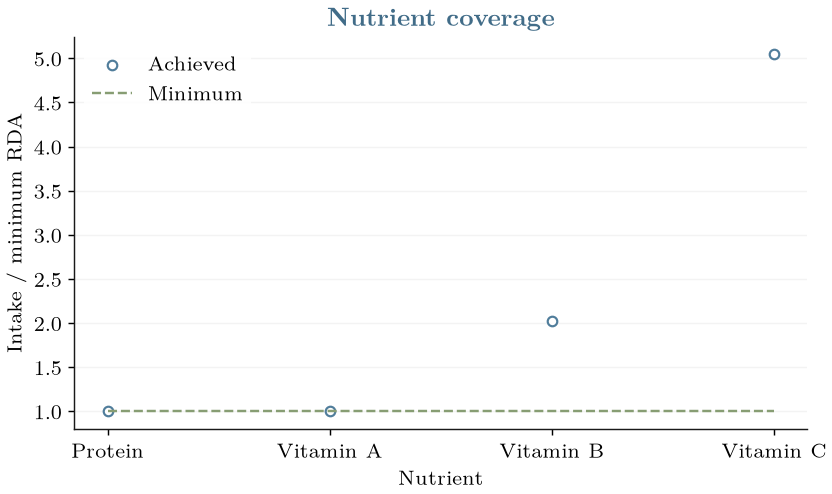

In [37]:
from gana.plotting import snapshot

amounts = snapshot(p.x).values
nutrients = {
    'Protein': (p.protein, 80),
    'Vitamin A': (p.vitA, 60),
    'Vitamin B': (p.vitB, 50),
    'Vitamin C': (p.vitC, 30),
}
coverage = [
    sum(
        amount * coefficient
        for amount, coefficient in zip(amounts, nutrient._)
    ) / minimum
    for nutrient, minimum in nutrients.values()
]
names = list(nutrients)
(
    p.scatter(coverage, x=names, label='Achieved')
    + p.line([1.0] * len(names), x=names, label='Minimum')
).with_options(
    title='Nutrient coverage', xlabel='Nutrient', ylabel='Intake / minimum RDA'
).show()